# Week 2 - Self-Driving Car: Cleaning, Steering EDA, Balancing, Split & Baseline

**Topics (record sections c, d, e)**
* c. Clean the image paths, analyse the steering-angle distribution, balance the data
* d. Exploratory data analysis on the train/test split
* e. A **mean baseline model** - the score any real model must beat

> Why this matters: if 70%+ of frames have steering ~0, a network can get a low loss by *always predicting ~0* and never learn to turn. Balancing the dataset forces it to learn curves too.

## Setup (repeat of Week 1)

In [1]:
import os, random, ntpath, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Dense, MaxPooling2D, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

random.seed(0); np.random.seed(0); tf.random.set_seed(0)

datadir = "data/selfdrive"
if not os.path.exists(os.path.join(datadir, "driving_log.csv")):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Aman-py/data.git", datadir], check=True)
print("Dataset folder ready:", os.path.exists(datadir))

columns = ["center", "left", "right", "steering", "throttle", "reverse", "speed"]
dataset = pd.read_csv(os.path.join(datadir, "driving_log.csv"), names=columns)

Dataset folder ready: True


## c1. Clean the image paths
`ntpath.split(path)` splits at the last `\` or `/` and returns `(folder, filename)`. We keep only the filename so the dataset works on any machine.

In [2]:
def removePath(path):
    base, tail = ntpath.split(path)
    return tail

dataset["center"] = dataset["center"].apply(removePath)
dataset["left"]   = dataset["left"].apply(removePath)
dataset["right"]  = dataset["right"].apply(removePath)
dataset.head()

,center,left,right,steering,throttle,reverse,speed
0,center_2018_10_17_16_36_30_865.jpg,left_2018_10_17_16_36_30_865.jpg,right_2018_10_17_16_36_30_865.jpg,0.0,0.0,0.0,0.000078
1,center_2018_10_17_16_36_30_966.jpg,left_2018_10_17_16_36_30_966.jpg,right_2018_10_17_16_36_30_966.jpg,0.0,0.0,0.0,0.000078
2,center_2018_10_17_16_36_31_098.jpg,left_2018_10_17_16_36_31_098.jpg,right_2018_10_17_16_36_31_098.jpg,0.0,0.0,0.0,0.000079
3,center_2018_10_17_16_36_31_253.jpg,left_2018_10_17_16_36_31_253.jpg,right_2018_10_17_16_36_31_253.jpg,0.0,0.0,0.0,0.000078
4,center_2018_10_17_16_36_31_366.jpg,left_2018_10_17_16_36_31_366.jpg,right_2018_10_17_16_36_31_366.jpg,0.0,0.0,0.0,0.000079


## c2. Histogram of steering angles
`np.histogram(values, 25)` divides [-1, 1] into 25 equal-width **bins** and counts the samples in each. It returns the counts (`hist`) and the 26 bin **edges** (`bins`).

In [3]:
num_bins = 25
hist, bins = np.histogram(dataset["steering"], num_bins)
print("Histogram counts:", hist)
print("Bin edges:", bins.round(2))

center = (bins[:-1] + bins[1:]) * 0.5       # midpoint of each bin, used as bar positions
print("Bin centers:", center.round(2))

Histogram counts: [  48   16   13   15   21   36   48   69  161  174  337  239 5454   56
  160   82   97   99   37   25   32   15   12    5    8]
Bin edges: [-1.   -0.92 -0.84 -0.76 -0.68 -0.6  -0.52 -0.44 -0.36 -0.28 -0.2  -0.12
 -0.04  0.04  0.12  0.2   0.28  0.36  0.44  0.52  0.6   0.68  0.76  0.84
  0.92  1.  ]
Bin centers: [-0.96 -0.88 -0.8  -0.72 -0.64 -0.56 -0.48 -0.4  -0.32 -0.24 -0.16 -0.08
  0.    0.08  0.16  0.24  0.32  0.4   0.48  0.56  0.64  0.72  0.8   0.88
  0.96]


A bar plot makes the imbalance obvious. The horizontal line at `threshold = 500` is the maximum number of samples we will allow per bin.

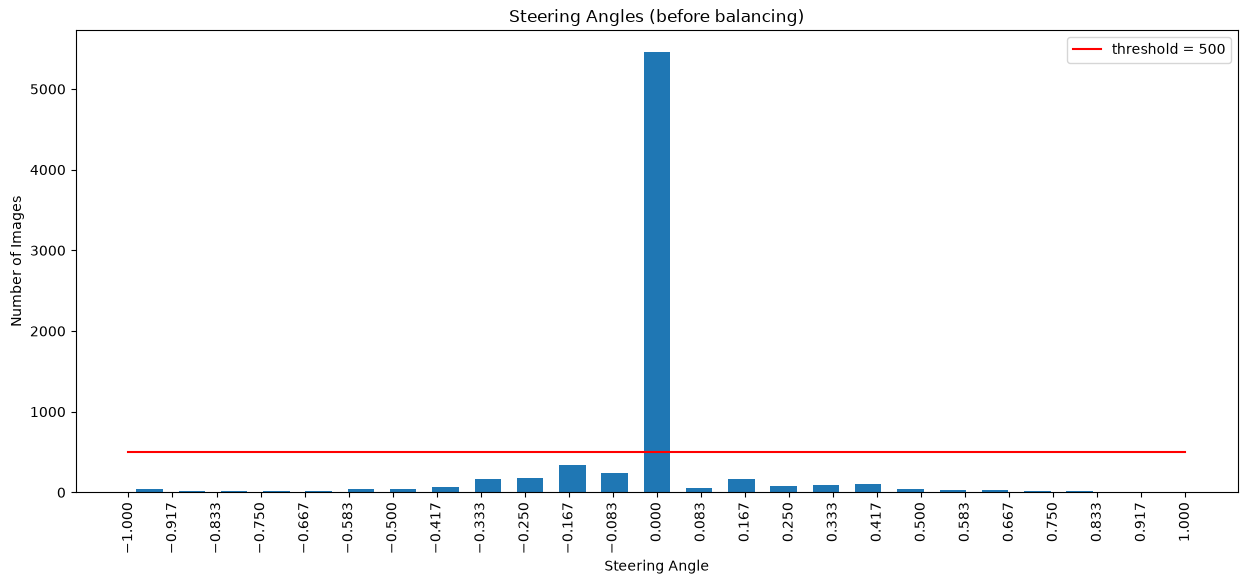

In [4]:
threshold = 500
plt.figure(figsize=(15, 6))
plt.bar(center, hist, width=0.05)
plt.xticks(np.linspace(-1, 1, 25), rotation=90)
plt.title("Steering Angles (before balancing)")
plt.xlabel("Steering Angle"); plt.ylabel("Number of Images")
plt.plot((dataset["steering"].min(), dataset["steering"].max()), (threshold, threshold), color="red", label="threshold = 500")
plt.legend(); plt.show()

## c3. Balance the data
Idea: for each bin, keep at most `threshold` samples and drop the rest at random.

Implementation notes
* `np.digitize` assigns each sample to exactly one bin (the record's double loop with `>= edge and <= edge` is slow and puts a sample sitting on an edge into two bins).
* `shuffle(..., random_state=42)` makes the *random* choice of which samples to drop repeatable.

> **Note - a bug fixed compared with the lab record.** In the record, `bin_indices = bin_indices[threshold:]` sits *inside* the `if len(bin_indices) > threshold:` block.
> So for every bin with **500 samples or fewer**, the slice is skipped and **all** of that bin's samples get added to `remove_list`.
> The result is that only the 500 "straight driving" images survive (steering ≈ 0 for all of them), which is why the record's baseline MSE is ~2e-6 and the model has nothing to learn.
> The fix: always slice (`idx[threshold:]` is simply empty for small bins), so only the *surplus* above the threshold is removed.

In [5]:
bin_id = np.clip(np.digitize(dataset["steering"], bins[1:-1]), 0, num_bins - 1)

remove_list = []
for i in range(num_bins):
    bin_indices = np.where(bin_id == i)[0]               # rows that fall in bin i
    bin_indices = shuffle(bin_indices, random_state=42)  # random order
    remove_list.extend(bin_indices[threshold:])          # everything beyond the first 500 is surplus

print("Samples to remove:", len(remove_list))
dataset = dataset.drop(dataset.index[remove_list]).reset_index(drop=True)
print("Dataset size after balancing:", len(dataset))

Samples to remove: 4954
Dataset size after balancing: 2305


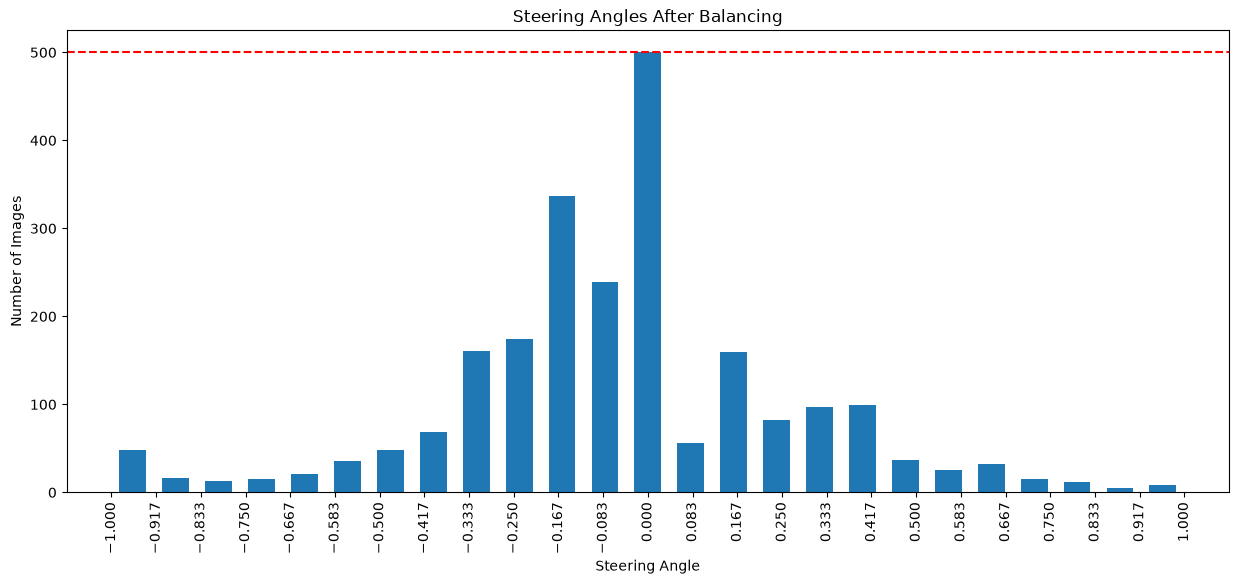

center      center_2018_10_17_16_36_32_664.jpg
left          left_2018_10_17_16_36_32_664.jpg
right        right_2018_10_17_16_36_32_664.jpg
steering                                   0.0
throttle                                   0.0
reverse                                    0.0
speed                                 0.000078
Name: 1, dtype: object

In [6]:
hist, _ = np.histogram(dataset["steering"], num_bins)
plt.figure(figsize=(15, 6))
plt.bar(center, hist, width=0.05)
plt.xticks(np.linspace(-1, 1, 25), rotation=90)
plt.title("Steering Angles After Balancing")
plt.xlabel("Steering Angle"); plt.ylabel("Number of Images")
plt.axhline(threshold, linestyle="--", color="red"); plt.show()
dataset.iloc[1]

## c4. Collect image paths and steering values
We only use the **center** camera. The function returns two aligned NumPy arrays: full image paths (X) and steering angles (y).

In [7]:
def loadImageSteering(datadir, dataset):
    imagePath, steeringPath = [], []
    for i in range(len(dataset)):
        center_image = dataset.iloc[i]["center"]
        steering = float(dataset.iloc[i]["steering"])
        imagePath.append(os.path.join(datadir, center_image))
        steeringPath.append(steering)
    return np.asarray(imagePath), np.asarray(steeringPath)

imagePath, steeringPath = loadImageSteering(os.path.join(datadir, "IMG"), dataset)
print("First image:", imagePath[0])
print("Number of images:", len(imagePath), "| steering values:", len(steeringPath))
print("File exists:", os.path.exists(imagePath[0]))

First image: data/selfdrive\IMG\center_2018_10_17_16_36_31_862.jpg
Number of images: 2305 | steering values: 2305
File exists: True


## d. Train/test split and EDA
80% of the data trains the network, 20% is held back to measure how well it generalises. `random_state=6` fixes the shuffle.
Then we check that train and test have a *similar* steering distribution - otherwise the test score would be misleading.

In [8]:
x_train, x_test, y_train, y_test = train_test_split(imagePath, steeringPath, test_size=0.2, random_state=6)
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 1844
Testing samples: 461


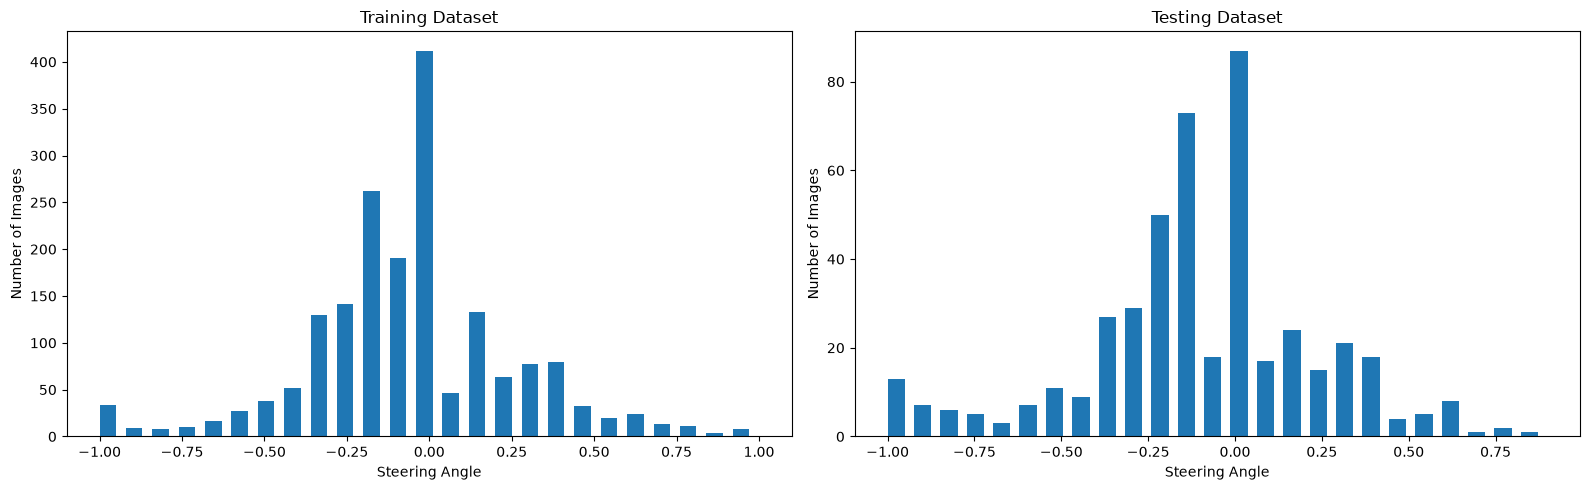

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=False)
for ax, y, name in zip(axs, [y_train, y_test], ["Training Dataset", "Testing Dataset"]):
    ax.hist(y, bins=num_bins, width=0.05)
    ax.set_title(name); ax.set_xlabel("Steering Angle"); ax.set_ylabel("Number of Images")
plt.tight_layout(); plt.show()

## e. Mean baseline model
The simplest possible "model": always predict the **mean steering angle of the training set**. Its **mean squared error (MSE)** on the test set is the number the CNN has to beat:

$$\text{MSE} = \frac{1}{n}\sum_i (y_i - \hat y_i)^2$$

In [10]:
mean_steering = np.mean(y_train)
baseline_predictions = np.full(len(y_test), mean_steering)
baseline_mse = np.mean((y_test - baseline_predictions) ** 2)

print("Mean steering angle (train):", mean_steering)
print("Baseline MSE on test set:", baseline_mse)

Mean steering angle (train): -0.04546927379229935
Baseline MSE on test set: 0.11740117013233528


## Summary
* Raw data was dominated by "drive straight" frames; we capped every steering bin at 500 samples.
* Split: train / test = 80 / 20, with matching distributions.
* **Baseline MSE** recorded - in Week 4 the NVIDIA CNN's test MSE is compared against it.